# Wielowymiarowe ujęcie zróżnicowania poziomu jakości życia w województwach w Polsce
---
## Projekt Zaliczeniowy - Statystyczna Analiza Danych

W pracy będziemy badać poziom jakości życia w polskich województwach. Pod uwage zostały wzięte zmienne reprezentujące dane sfery życia: samorząd, rynek pracy, warunki mieszkaniowe, społeczeńswto, bezpieczeństwo, środowisko, sport i rekreacja, przedsiebiorczość, i warunki materialne.

Analiza jest inspirowana publikacją naukową pt.: "Wielowymiarowe ujęcie zróżnicowania poziomu jakości życia w województwach w Polsce" autorstwa Elżbiety Roszko-Wójtowicz i Marii M. Grzelak z Uniwersytetu Łódzkiego.

Celem pracy jest zbadanie województw pod kątem atrakcyjności dla przecętnego mieszkańca, wyodrębnienie najlepszych i najgorszych obszarów pod tym kątem, porównanie wyników z wyżej wymienioną analizą.

In [20]:
import os
import pandas as pd
import numpy as np
from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

---

## 0. Przygotowanie danych

In [7]:
catalog = "./data"
csv_files = []
var_name_list = []

with os.scandir(catalog) as entries:
    for entry in entries:
        if entry.is_file() and entry.name.endswith(".csv"):
            csv_files.append(entry.path)

df_2015 = None
df_2024 = None
i = 1

for file in csv_files:
    var_name = os.path.basename(file).replace(".csv", "")
    var_name_list.append(var_name)
    df = pd.read_csv(file, sep=";")

    column_2015 = [c for c in df.columns if '2015' in c][0]
    column_2024 = [c for c in df.columns if '2024' in c][0]
    df[column_2015] = pd.to_numeric(df[column_2015].astype(str).str.replace(',', '.').str.strip(), errors='coerce')
    df[column_2024] = pd.to_numeric(df[column_2024].astype(str).str.replace(',', '.').str.strip(), errors='coerce')

    temp_2015 = pd.DataFrame()
    temp_2024 = pd.DataFrame()

    temp_2015['Nazwa'] = df['Nazwa'].copy()
    temp_2015[f'X{i} {var_name}'] = df[column_2015].copy()

    temp_2024['Nazwa'] = df['Nazwa'].copy()
    temp_2024[f'X{i} {var_name}'] = df[column_2024].copy()

    if df_2015 is None:
        df_2015 = temp_2015
        df_2024 = temp_2024
    else:
        df_2015 = pd.merge(df_2015, temp_2015, on='Nazwa')
        df_2024 = pd.merge(df_2024, temp_2024, on='Nazwa')

    i += 1

df_2015 = df_2015.set_index('Nazwa')[:-1]
df_2024 = df_2024.set_index('Nazwa')[:-1]

Wynik: dane są przygotowane w osobnych ramkach danych z względu na aktualność danych. W publikacji która stanowi nasz odnośnik wykorzystywany jest: "Wskaźnik wykrywalności przestepstw kryminalnych". My wzieliśmy pod uwagę przestepców, ponieważ GUS nie udostepnia już wskaźnika o takiej nazwie.

---

## 1. Wprowadzenie - dane

$X1$ - Emisja zanieczyszczeń pyłowych na 1 km2 **[emisja_pylkow]**

$X2$ - Gęstość zaludnienia (os./km2) **[gestosc_zaludnienia]**

$X3$ - Nakłady inwestycyjne na jednego mieszkańca (zł) **[naklady_inwestycyjne]**

$X4$ - Liczba zarejestrowanych podmiotów gospodarczych w przeliczeniu na 1000 mieszka **[podmioty_gospodarcze]**

$X5$ - Powierzchnia mieszkań oddanych do użytku w m2 na jednego mieszkańca (m2/os.) **[powierzchnia_mieszkaniowa]**

$X6$ - Wskaźnik wykrywalności przestępstw kryminalnych (%) **[przestepstwa]**

$X7$ - Średnie wynagrodzenie brutto (zł) **[srednie_wynagrodzenie]**

$X8$ - Liczby bezrobotnych w liczbie osób w wieku produkcyjnym (%) **[stopa_bezrobocia]**

$X9$ - Udział parków, zieleńców i terenów zieleni osiedlowej w powierzchni ogółem (%) **[udzial_zieleni_w_powierzchni]**

---

## 2. Statystyka Opisowa

### 2.1 Dodanie funkcji liczącej wszystkie statystyki

Podstawowe miary statystyki opisowej dla każdej zmiennej diagnostycznej:

$\bar{x}$ – średnia arytmetyczna

$M_e$ – mediana

$S_x$ – odchylenie standardowe z próby

$V_s$ – klasyczny współczynnik zmienności

$K$ – kurtoza

$A_s$ – współczynnik asymetrii / skośność

$MIN$ – wartość minimalna wraz z nazwą województwa

$MAX$ – wartość maksymalna wraz z nazwą województwa

Nie będziemy sprawdzać czy istnieją braki w danych (możemy od razu zauważyć, że takowe nie występują), oraz rozważać wartości odstających ze względu na charakter danych.

In [8]:
def oblicz_statystyki_opisowe(df, rok):
    stat = []
    for col in df.columns:
        s = df[col]
        stat.append({
            'Zmienna': col,
            'Rok': rok,
            'Średnia': s.mean(),
            'Mediana': s.median(),
            'Odchylenie standardowe': s.std(),
            'Wspołczynnik zmienności': s.std()/s.mean() if s.mean()!=0 else 0,
            'Kurtoza': s.kurtosis(),
            'Skośność': s.skew(),
            'Max': f"{s.idxmax()}: {s.max()}",
            'Min': f"{s.idxmin()}: {s.min()}"
        })
    return pd.DataFrame(stat)

tabela1 = oblicz_statystyki_opisowe(df_2015, '2015')
tabela2 = oblicz_statystyki_opisowe(df_2024, '2024')

tabela = pd.concat([tabela1, tabela2], ignore_index=True)
tabela = tabela.sort_values(by=['Zmienna', 'Rok']).reset_index(drop=True)
tabela = tabela.set_index(['Zmienna', 'Rok'])

display(tabela)

Średnia  Mediana  \
Zmienna                         Rok                      
X1 emisja_pylkow                2015     0.16     0.13   
                                2024     0.06     0.04   
X2 gestosc_zaludnienia          2015   129.24   116.30   
                                2024   124.61   113.00   
X3 naklady_inwestycyjne         2015  6613.19  6414.00   
                                2024 10740.50 10477.50   
X4 podmioty_gospodarcze         2015   103.88   101.50   
                                2024   133.38   125.50   
X5 powierzchnia_mieszkaniowa    2015    26.73    26.65   
                                2024    31.83    31.95   
X6 przestepstwa                 2015    66.26    66.65   
                                2024    70.52    70.20   
X7 srednie_wynagrodzenie        2015  3857.65  3757.23   
                                2024  8164.46  7922.77   
X8 stopa_bezrobocia             2015    10.68    10.40   
                                2024     3.87     3.85   
X9 udzial_zieleni_w_powierzchni 2015     0.21     0.20   
                                2024     0.22     0.20   

                                      Odchylenie standardowe  \
Zmienna                         Rok                            
X1 emisja_pylkow                2015                    0.18   
                                2024                    0.06   
X2 gestosc_zaludnienia          2015                   76.17   
                                2024                   73.26   
X3 naklady_inwestycyjne         2015                 1517.69   
                                2024                 3031.41   
X4 podmioty_gospodarcze         2015                   19.04   
                                2024                   24.55   
X5 powierzchnia_mieszkaniowa    2015                    1.54   
                                2024                    1.55   
X6 przestepstwa                 2015                    5.85   
                                2024                    5.10   
X7 srednie_wynagrodzenie        2015                  405.97   
                                2024                  660.79   
X8 stopa_bezrobocia             2015                    2.60   
                                2024                    0.99   
X9 udzial_zieleni_w_powierzchni 2015                    0.17   
                                2024                    0.14   

                                      Wspołczynnik zmienności  Kurtoza  \
Zmienna                         Rok                                      
X1 emisja_pylkow                2015                     1.14    13.69   
                                2024                     0.96    10.89   
X2 gestosc_zaludnienia          2015                     0.59     6.77   
                                2024                     0.59     5.49   
X3 naklady_inwestycyjne         2015                     0.23     3.18   
                                2024                     0.28     9.14   
X4 podmioty_gospodarcze         2015                     0.18    -0.61   
                                2024                     0.18     0.18   
X5 powierzchnia_mieszkaniowa    2015                     0.06    -0.42   
                                2024                     0.05     0.00   
X6 przestepstwa                 2015                     0.09     0.04   
                                2024                     0.07    -1.05   
X7 srednie_wynagrodzenie        2015                     0.11     5.33   
                                2024                     0.08     2.99   
X8 stopa_bezrobocia             2015                     0.24    -0.16   
                                2024                     0.26    -1.30   
X9 udzial_zieleni_w_powierzchni 2015                     0.82    11.51   
                                2024                     0.65     9.48   

                                      Skośność                        Max  \
Zmienna                         Rok   

### 2.2 Analiza statystyk opisowych

In [9]:
display(tabela.loc[['X1 emisja_pylkow']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna          Rok                                              
X1 emisja_pylkow 2015     0.16     0.13                    0.18   
                 2024     0.06     0.04                    0.06   

                       Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna          Rok                                                
X1 emisja_pylkow 2015                     1.14    13.69      3.58   
                 2024                     0.96    10.89      3.08   

                                 Max                        Min  
Zmienna          Rok                                             
X1 emisja_pylkow 2015  ŚLĄSKIE: 0.83  WARMIŃSKO-MAZURSKIE: 0.04  
                 2024  ŚLĄSKIE: 0.25  WARMIŃSKO-MAZURSKIE: 0.01

Patrząc na średnią czy medianę dla obu lat, wartość tego wskaźnika jest niska. Widzimy spadek o 0.1 w średniej i 0.08 w medianie. Emisja pyłków dla poszczegółnych województw mocno sie waha. Możemy to stwierdzić po dużej wartości odchylenia standardowego, jak i różnicy między maksymalną i minimalną wartością. Jeśli chodzi o województwa dla których te wyniki są osiągane, śląskie i warmińsko-mazurskie, to te obszary nie stanowią zaskoczenia. Wpływa na to przemysł, gęste zaludnie, ogrzewanie węglowe i ukształtowania terenu na Śląsku, oraz jeśli chodzi o Mazury - duża ilość jezior i zalesienie sprzyjają czystszemu powietrzu. Współczynnik zmienności mówi nam również o ogromnym zróznicowaniu województw pod kątem zanieczyszczeń pyłowych (ponad 100% w 2015, w 2024 ta wartośc zmalała, nadal jednak sięga prawie 100%). Obserwujemy także skośność prawostronną. Oznacza to, że w większości województw emisja pyłków jest na poziomie ponieżej średniej. Widzimy także, że często występują wartości odstające (reprezentuje je np. woj. Śląskie), ale również duża część odczytów koncentruję się wokół średniej. Na przestrzeni tych 9 lat możemy także obserwować zmiejszenie się dysproporcji zanieczyszcenia powietrza województwami między. Wynika to prawdopodnie z rosnącej świadomości ekologicznej jak i idących za tym przepisów prawnych.
display(tabela.loc[['X1 emisja_pylkow']])

In [10]:
display(tabela.loc[['X2 gestosc_zaludnienia']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna                Rok                                              
X2 gestosc_zaludnienia 2015   129.24   116.30                   76.17   
                       2024   124.61   113.00                   73.26   

                             Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna                Rok                                                
X2 gestosc_zaludnienia 2015                     0.59     6.77      2.37   
                       2024                     0.59     5.49      2.15   

                                        Max                        Min  
Zmienna                Rok                                              
X2 gestosc_zaludnienia 2015  ŚLĄSKIE: 370.6            PODLASKIE: 58.9  
                       2024  ŚLĄSKIE: 347.9  WARMIŃSKO-MAZURSKIE: 55.8

Widzimy, ze wartość tego wskaźnika osiąga warości umiarkowane, jeśli patrzymy na średnią czy medianę. Gęstość zaludnienia mocno się jednak waha między województwami (odchylenie standardowe stanowy przeszło połowę średniej, wysoki współczynnik zmienności, który nie zmienił się na przestrzeni lat). Po raz kolejny mamy tu do czynienia ze skośnoscią prawostronną. Kurtoza osiąga niższe warości dla analizowanego wskaźnika, lecz nadal jest wysoka, zwłaszcza w 2015. Świadczy to o grubych ogonach i istnieniu outlinerów. Przykładem takiego outlinera jest województwo Śląskie z ok. 3 razy większą gęstością zaludnienia w porównaniu do średniej. Naprzeciw wychodzi woj. podlaskie (2015) i woj. warmińsko-mazurskie (2024) z wynikiem o około połowę mniejszym od średniej. Oba te przypadki wpływają na wartość kurtozy i skośności. Te różnice wyniką m.in z wielkości województw, urbanizacji, ukształtowania terenu.

In [11]:
display(tabela.loc[['X3 naklady_inwestycyjne']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna                 Rok                                              
X3 naklady_inwestycyjne 2015  6613.19  6414.00                 1517.69   
                        2024 10740.50 10477.50                 3031.41   

                              Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna                 Rok                                                
X3 naklady_inwestycyjne 2015                     0.23     3.18      1.38   
                        2024                     0.28     9.14      2.70   

                                             Max                        Min  
Zmienna                 Rok                                                  
X3 naklady_inwestycyjne 2015  MAZOWIECKIE: 10868       ŚWIĘTOKRZYSKIE: 4624  
                        2024  MAZOWIECKIE: 20911  WARMIŃSKO-MAZURSKIE: 7741

Jeśli chodzi o nakłady inwestycyjne na 1 mieszkańca średnio prawie 7000 zł (2015) i 11 000zł (2024), to dobry wynik. Rok 2015 jest rokiem w którym możemy zaobserwować mniejsze dysproporcje niż w 2024. Współczynnik zmienności mówi nam o małej lub umiarkowanej zmienności, lecz widzimy wzrost wartości kurtozy i skośności w rozważanych okresach. Potwierdza to również różnica między wartością maksymalną i minimalną (w 2015 około 6 tys., w 2024 około 13 tys.). Województwo mazowieckie utrzymało swoją pozycję jako lidera w tej kategorii (co jest naturalną konsekwencją koncentracji kapitału w regionie stołecznym).

In [12]:
display(tabela.loc[['X4 podmioty_gospodarcze']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna                 Rok                                              
X4 podmioty_gospodarcze 2015   103.88   101.50                   19.04   
                        2024   133.38   125.50                   24.55   

                              Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna                 Rok                                                
X4 podmioty_gospodarcze 2015                     0.18    -0.61      0.48   
                        2024                     0.18     0.18      0.82   

                                           Max                Min  
Zmienna                 Rok                                        
X4 podmioty_gospodarcze 2015  MAZOWIECKIE: 143   PODKARPACKIE: 78  
                        2024  MAZOWIECKIE: 191  PODKARPACKIE: 104

Zarejestrowane podmioty gospodarcze w przeliczeniu na 1000 mieszkańców reprezentują w naszej analizie stan przedsiębiorczości Polaków. Patrząc na tabele możemy dostrzec, że kształtuje się na umiarkowanym poziomie. Niskie odchylenie standarodowe, współczynnik zmienności, mała różnica między maksumum i minimum oraz ujemna kurtoza wskazują na spłaszczony rozkład wyników i brak drastycznych wartości odstających między regionami. Po raz kolejny najwększy wynik osiąga mazowieckie, na ostatnim miejscu plasuje się podkarpackie.

In [13]:
display(tabela.loc[['X5 powierzchnia_mieszkaniowa']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna                      Rok                                              
X5 powierzchnia_mieszkaniowa 2015    26.73    26.65                    1.54   
                             2024    31.83    31.95                    1.55   

                                   Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna                      Rok                                                
X5 powierzchnia_mieszkaniowa 2015                     0.06    -0.42     -0.19   
                             2024                     0.05     0.00     -0.48   

                                                 Max  \
Zmienna                      Rok                       
X5 powierzchnia_mieszkaniowa 2015  MAZOWIECKIE: 29.5   
                             2024  MAZOWIECKIE: 34.5   

                                                         Min  
Zmienna                      Rok                              
X5 powierzchnia_mieszkaniowa 2015  WARMIŃSKO-MAZURSKIE: 23.9  
                             2024  WARMIŃSKO-MAZURSKIE: 28.6

Jeśli chodzi o Polskę, średnia powierzchnia mieszkaniowa wynosząca blisko 30 , to przeciętny wynik. W porówaniu do standardu europejskiego (35 - 40 ) wynik ten klasuję się poniżej średniej. Po wartości pozostałych wskażników, możemy stwierdzić, że nie ma istotnych różnic między województwami. Mamy małe odchylenie standarowe, niski współczynnik zmieności, mało outlinerów, wartości naszego wskażnika są raczej skoncentrowane, z tendencją bycia wyższymi od średniej. Biorąc pod uwage maksymalną i minimalną wartość, ona województwa zachowały swoje pozycje.

In [14]:
display(tabela.loc[['X6 przestepstwa']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna         Rok                                              
X6 przestepstwa 2015    66.26    66.65                    5.85   
                2024    70.52    70.20                    5.10   

                      Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna         Rok                                                
X6 przestepstwa 2015                     0.09     0.04     -0.53   
                2024                     0.07    -1.05     -0.18   

                                       Max                Min  
Zmienna         Rok                                            
X6 przestepstwa 2015  ŚWIĘTOKRZYSKIE: 76.4  MAZOWIECKIE: 53.8  
                2024     MAŁOPOLSKIE: 78.0  MAZOWIECKIE: 61.8

Wkaźnik wykrywalności sprawców przestępstw kryminalnych wynoszący średnio około 70% w obu latach to dobry wynik. Nie mamy tu do czynienia z wysokim zróżnicowaniem między województwami, mało wartości odstających, są one raczej skoncentrowane. Widzimy tendencję wartości wskaźnika do bycia zbliżonym do średniej w wielu województwach. Lekka skośność lewostronna, ale rozkła jest zbliżony do normalnego w obu latach (zwłaszcza w 2024). Najbezpiecznijsze województwa to świętokrzystkie i małopolskie. Po drugiej stronie znajduje się mazowieckie.

In [15]:
display(tabela.loc[['X7 srednie_wynagrodzenie']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna                  Rok                                              
X7 srednie_wynagrodzenie 2015  3857.65  3757.23                  405.97   
                         2024  8164.46  7922.77                  660.79   

                               Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna                  Rok                                                
X7 srednie_wynagrodzenie 2015                     0.11     5.33      2.10   
                         2024                     0.08     2.99      1.64   

                                                 Max  \
Zmienna                  Rok                           
X7 srednie_wynagrodzenie 2015   MAZOWIECKIE: 5098.55   
                         2024  MAZOWIECKIE: 10018.71   

                                                        Min  
Zmienna                  Rok                                 
X7 srednie_wynagrodzenie 2015  WARMIŃSKO-MAZURSKIE: 3495.02  
                         2024         PODKARPACKIE: 7514.69

Średnie wynagrodzenie brutto wzrosło w ciągu 9 lat ponad dwukrotnie, co ma związek m.in. z inflacją oraz wzrostem kosztów utrzymania. Zróżnicowanie między województwami w ramach tego wskaźnika jest stosunkowo małe. Występują jednak wartości odstające, ltóre wpływają na wynik kurtozy w 2015 roku. W tym okresie możemy także zaobserwować większą skośność prwostronną niż w 2024 roku. Możemy z tego wywnioskować, że pomimo ogólnego wzrostu płac i kosztów życia, dysproporcje płacowe między województwami powoli maleją.

In [16]:
display(tabela.loc[['X8 stopa_bezrobocia']])

Średnia  Mediana  Odchylenie standardowe  \
Zmienna             Rok                                              
X8 stopa_bezrobocia 2015    10.68    10.40                    2.60   
                    2024     3.87     3.85                    0.99   

                          Wspołczynnik zmienności  Kurtoza  Skośność  \
Zmienna             Rok                                                
X8 stopa_bezrobocia 2015                     0.24    -0.16      0.29   
                    2024                     0.26    -1.30     -0.01   

                                                Max                 Min  
Zmienna             Rok                                                  
X8 stopa_bezrobocia 2015  WARMIŃSKO-MAZURSKIE: 16.2  WIELKOPOLSKIE: 6.1  
                    2024          PODKARPACKIE: 5.5  WIELKOPOLSKIE: 2.3

Widzimy, że stopa bezrobocia zmalała prawie trzykrotnie w okresie 2015 - 2024. Odchylenie standardowe tego wskaźnika także zmalało, choć współczynnik zmienności nieznacznie wzrósł. Wynosi on jednak 24 - 25%, co wciąż pozwala uznać populację za stosunkowo jednorodną pod tym względem. Zmiana wartości skośności pokazuje ewolucję rozkładu względem średniej (w 2015 r. występujeła lekka skośność prawostronna, w 2024 r. rozkład jest bardziej symetryczny). Ponieważ wartości skośności w obu latach są bliskie zera, układ można uznać za zbliżony do normalnego.

In [17]:
display(tabela.loc[['X9 udzial_zieleni_w_powierzchni']])

Średnia  Mediana  \
Zmienna                         Rok                      
X9 udzial_zieleni_w_powierzchni 2015     0.21     0.20   
                                2024     0.22     0.20   

                                      Odchylenie standardowe  \
Zmienna                         Rok                            
X9 udzial_zieleni_w_powierzchni 2015                    0.17   
                                2024                    0.14   

                                      Wspołczynnik zmienności  Kurtoza  \
Zmienna                         Rok                                      
X9 udzial_zieleni_w_powierzchni 2015                     0.82    11.51   
                                2024                     0.65     9.48   

                                      Skośność           Max             Min  
Zmienna                         Rok                                           
X9 udzial_zieleni_w_powierzchni 2015      3.19  ŚLĄSKIE: 0.8  LUBELSKIE: 0.1  
                                2024      2.79  ŚLĄSKIE: 0.7  LUBELSKIE: 0.1

Średni udział zieleni w powierzchni ogółem nieznacznie się zmienił w ciągu analizowanyh lat. Stabilność tego wskaźnika świadczy o stałym utrzymywaniu miejskiej infrastruktury zielonej w regionach. Najwyższą wartość wskaźnika odnotowujemy w województwie śląskim (0,8% w 2015 r. oraz 0,7% w 2024 r.). Wynika to z faktu, że Śląsk jest regionem o najwyższym stopniu urbanizacji i zagęszczenia miast, co wiąże się z zagęszczeniem osiedli oraz rozbudowaną siecią parków miejskich i zieleńców. Najmniejsza wartość przypada niezmiennie lubelskiemu, co wiąże się z jego silnie rolniczym charakterem (duży udział gruntów ornych kosztem zwartych kompleksów leśnych). Na uwagę zasługuje wysoka kurtoza, świadcząca o obecności wartości odstających, oraz znaczna niejednorodność populacji (współczynnik zmienności na poziomie 63–83%).

### 2.3 Analiza macierzy korelacji

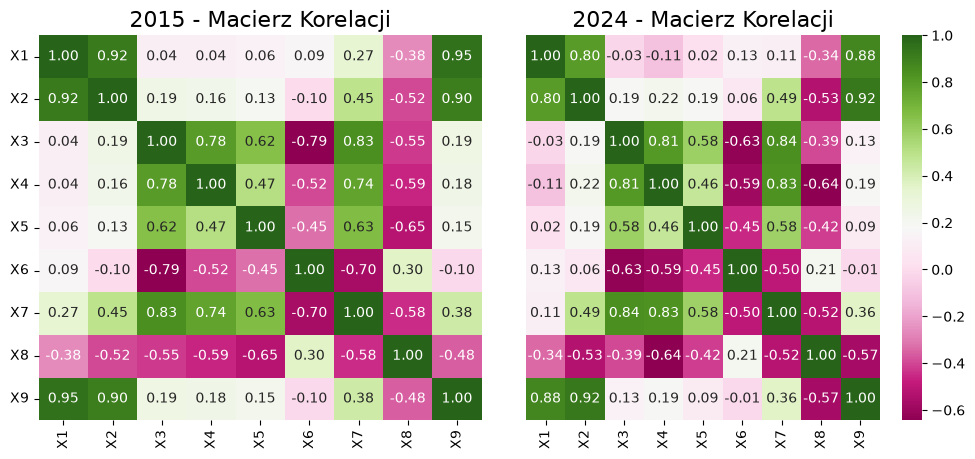

In [18]:
corr_2015 = df_2015.corr()
corr_2024 = df_2024.corr()

fig, axes = plt.subplots(ncols = 2,  figsize=(12, 5))
ax1, ax2 = axes

sns.heatmap(corr_2015, annot=True, fmt=".2f", cmap="PiYG", ax=ax1, cbar=False)
ax1.set_title('2015 - Macierz Korelacji', fontsize=16)
ax1.set_xticklabels([label[:2] for label in corr_2015])
ax1.set_yticklabels([label[:2] for label in corr_2015])

sns.heatmap(corr_2024, annot=True, fmt=".2f", cmap="PiYG", ax=ax2, yticklabels=False)
ax2.set_title('2024 - Macierz Korelacji', fontsize=16)
ax2.set_xticklabels([label[:2] for label in corr_2024])

plt.subplots_adjust(wspace=0.1)

plt.show()

Wstępna analiza macierzy korelacji pokazuje, jak powiązane są ze sobą wybrane wskaźniki jakości życia oraz czy na przestrzeni lat (2015 vs. 2024) te relacje pozostały równe. Zauważalna jest bardzo silna dodatnia korelacja pomiędzy emisją pyłów ($X1$), gęstością zaludnienia ($X2$) oraz udziałem terenów zielonych ($X9$). Współczynniki sięgają tutaj wartości od 0,80 do 0,95. Regiony gęściej zaludnione to obszary wysoce zurbanizowane. Z jednej strony generują większe zanieczyszczenia przemysłowo-komunikacyjne ($X1$), a z drugiej posiadają największy odsetek skatalogowanych zieleńców i parków miejskich ($X9$). Relacja ta pozostała niemal niezmienna w obu badanych latach. Wskaźniki ekonomiczne wykazują silną, logiczną spójność. Wysokie nakłady inwestycyjne ($X3$), przedsiębiorczość mieszkańców ($X4$) oraz wysokie wynagrodzenia ($X7$) wyraźnie idą w parze. Zmienne te sprzyjają rynkowi mieszkalnemu ($X5$ wykazuje dodatnie korelacje z inwestycjami i płacami) oraz wyraźnie ograniczają bezrobocie ($X8$ ma ujemne korelacje z całym blokiem gospodarczym).

Wskaźnik wykrywalności przestępstw ($X6$) koreluje ujemnie z poziomem zamożności i inwestycji . Wynika to ze specyfiki regionalnej – w dużych, bogatych aglomeracjach rejestruje się więcej anonimowych przestępstw trudniejszych do natychmiastowego wykrycia niż w mniejszych, spokojniejszych ośrodkach. Struktura powiązań między cechami w 2015 roku i 2024 roku jest bardzo zbliżona. Oznacza to, że mechanizmy kształtujące jakość życia w województwach mają charakter stabilny na przestrzeni ostatnich 10 lat.

---

## 3. Porządkowanie liniowe

### 3.1 Stymulanty i Destymulanty

| $X$ | Zmienna | Kategoria | Kierunek Wpływu |
| --- | --- | --- | --- |
| $X1$ | emisja_pylow | Środowisko | Destymulanta |
| $X2$ | gestosc_zaludnienia | Społeczeństwo | Stymulanta |
| $X3$ | naklady_inwestycyjne | Samorząd | Stymulanta |
| $X4$ | podmioty_gospodarcze | Przedsiębiorczość | Stymulanta |
| $X5$ | powierzchnia_mieszkaniowa | Warunki mieszkaniowe | Stymulanta |
| $X6$ | przestepstwa | Bezpieczeństwo | Stymulanta |
| $X7$ | srednie_wynagrodzenie | Warunki materialne | Stymulanta |
| $X8$ | stopa_bezrobocia | Rynek pracy | Destymulanta |
| $X9$ | udzial_zieleni_w_powierzchni | Sport i Rekreacja | Stymulanta |


#### 3.2 Metoda Hellwiga (dla 2015 i 2024)

In [26]:
def utworz_miernik_hellwiga(df):
    # 1. Zmianna destymulant na stymulanty
    temp = df.copy()
    for col in temp.columns:
        if col in ['emisja_pylow', 'stopa_bezrobocia']:
            temp[col] = temp[col]*(-1)

    # 2. Standaryzacja danych
    def standaryzacja_danych(df):
        for col in df.columns:
            df[col] = (df[col] - df[col].mean())/df[col].std()
        return df

    norm = standaryzacja_danych(temp)

    # 3. Obliczenie najlepszego obiektu (wzorca)
    wzorzec = {}
    for col in norm.columns:
        wzorzec[col] = norm[col].max()

    # 4. Obliczenie odległości poszczególnych obiektów od wzorca
    p0 = pd.Series(wzorzec)
    d = np.sqrt(((norm-p0)**2).sum(axis=1))

    # 5. Stworzenie odległości “możliwie dalekiej”
    d0 = d.mean() + 2*d.std()

    # 6. Wyznaczenie wartości miary dla każdego obiektu
    s = 1 - d/d0

    ranking_hellwig = pd.DataFrame(
        {
        'Nazwa': s.index,
        'Miernik_Hellwiga': s.values
        })

    ranking_hellwig = ranking_hellwig.sort_values(by='Miernik_Hellwiga', ascending=False).reset_index(drop=True)
    ranking_hellwig['Pozycja'] = range(1, len(ranking_hellwig)+1)
    return ranking_hellwig

r_2015 = utworz_miernik_hellwiga(df_2015)
r_2024 = utworz_miernik_hellwiga(df_2024)

tabela = pd.merge(r_2015, r_2024, on='Nazwa', suffixes=('_2015', '_2024'))
tabela['Zmiana pozycji'] = tabela['Pozycja_2015'] - tabela['Pozycja_2024']
tabela = tabela.sort_values(by='Pozycja_2024').reset_index(drop=True)

display(tabela)

,Nazwa,Miernik_Hellwiga_2015,Pozycja_2015,Miernik_Hellwiga_2024,Pozycja_2024,Zmiana pozycji
0,ŚLĄSKIE,0.48,1,0.45,1,0
1,MAZOWIECKIE,0.28,3,0.35,2,1
2,MAŁOPOLSKIE,0.26,4,0.32,3,1
3,DOLNOŚLĄSKIE,0.30,2,0.28,4,-2
4,POMORSKIE,0.22,6,0.23,5,1
5,OPOLSKIE,0.25,5,0.23,6,-1
6,ZACHODNIOPOMORSKIE,0.21,9,0.21,7,2
7,ŁÓDZKIE,0.21,8,0.20,8,0
8,WIELKOPOLSKIE,0.21,7,0.19,9,-2
9,KUJAWSKO-POMORSKIE,0.17,10,0.17,10,0


Zastosowanie metody Hellwiga pozwoliło sprowadzić 9 zmiennych diagnostycznych do jednego syntetycznego wskaźnika jakości życia, przyjmującego wartości z przedziału $[0, 1]$. Im wyższa wartość miernika, tym dane województwo znajduje się bliżej hipotetycznego, idealnego wzorca rozwoju.

Zestawienie wyników dla lat 2015 i 2024 pozwala podzielić województwa na wyraźne grupy oraz zaobserwować stabilność i dynamikę zachodzących zmian:

- Pozycje czołową w obu badanych latach utrzymało województwo śląskie. Wysoki wynik tego regionu wynika przede wszystkim z silnej koncentracji infrastruktury miejskiej, dużej gęstości zaludnienia oraz znacznego udziału terenów zieleni urządzonej, co w modelu wzorcowym mocno przybliża go do wartości maksymalnych. Województwa mazowieckie  oraz małopolskie  odnotowały największy progres wartości miernika. Regiony te dynamicznie nadrabiają dystans do lidera, opierając swój rozwój na wysokich zarobkach, intensywnym budownictwie mieszkaniowym i napływie inwestycji. Wojewódzctwo dolnośląskie zanotowało spadek co jednak nie oznacza pogarszającymi się warunkami życia, jedynie polepszeniem wcześniej wymienionych regionów.
- Województwa zajmujące pozycje od 5. do 11. charakteryzują się bardzo wyrównanymi i stabilnymi w czasie wartościami miernika. Warto odnotować awans województwa zachodniopomorskiego o dwa miejsca w górę oraz lekki spadek wielkopolskiego.
- Ostatnie miejsca składają się z wojewodzctw: świętokrzyskie, podlaskie, lubelskie, podkarpackie oraz zamykające tablice warmińsko-mazurskie. Pomimo korzystnych parametrów środowiskowych, niższy poziom płac, mniejsze nakłady inwestycyjne i słabsza dynamika budownictwa mieszkaniowego przełożyły się na niskie wartości syntetyczne.

Mimo upływu 9 lat generalny układ rankingu cechuje się dużą powtarzalnością. Aż 6 województw nie zmieniło swojej pozycji, a większość pozostałych przesunęła się zaledwie o miejsce czy dwa.

---

## 4. Analiza skupień

### 4.1 Grupowanie podziałowe - metoda k-medoid

Dzięki powyższej analizie możemy zauważyć, że istnieją województwa, które można określić jako wartości odstające. Z tego względu zastosujemy metodę k-medoid

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score

def k_medoid (df):
    df_scaled = StandardScaler().fit_transform(df)
    sil_core = -1
    k = 0
    for i in range(2,6):
        kmedoids = KMedoids(n_clusters=i, random_state=42, metric='euclidean')
        labels = kmedoids.fit_predict(df_scaled)
        if len(set(labels)) < i:
            continue
        score = silhouette_score(df_scaled, labels) #metoda sylwetki
        if (score > sil_core):
            sil_core = score
            k = i
    kmedoids = KMedoids(n_clusters=k, random_state=42, metric='euclidean')
    df['Skupienie'] = kmedoids.fit_predict(df_scaled)


k_medoid(df_2015)
tabela_medoid_2015 = df_2015.groupby('Skupienie').mean()
display(tabela_medoid_2015)
grupy_wojewodztw_2015 = df_2015.groupby('Skupienie').apply(lambda x: list(x.index)).reset_index(name='Województwa')
for idx, row in grupy_wojewodztw_2015.iterrows():
    print(f"Skupienie {row['Skupienie']}: {', '.join(row['Województwa'])}")

